# 🇿🇦 IDA117V: Question 1 & 2 — Problem Framing, Data Audit & Exploratory Data Analysis
**Module:** Introduction to Data Science (IDA117V) | Semester 2, 2026  
**Project Title:** Municipal Basic Service-Delivery Outage & Infrastructure Vulnerability Triage System  
**Authors:** MM Masemola (218615937), B Mdluli (222012937), M Mammburu (219952058), ME Maleke (219868499), PA Mavhungu (220527930)  
**Submission Date:** 20 October 2026  

---


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

BASE_DIR = os.path.dirname(os.path.abspath(''))
DATA_PATH = os.path.join(BASE_DIR, 'data', 'processed', 'clean_service_delivery.csv')
FIG_DIR = os.path.join(BASE_DIR, 'figures')
REPORTS_DIR = os.path.join(BASE_DIR, 'reports')

print(f"Loading audited data from: {DATA_PATH}")
df = pd.read_csv(DATA_PATH)
print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")


Loading audited data from: c:\Users\mavhu\.gemini\antigravity\scratch\autograder\ida117v_project\data\processed\clean_service_delivery.csv
Dataset Dimensions: 3500 rows, 18 columns
Duplicates detected: 5 (0.14%) removed -> N=3500 unique ward records.


## 1. Data Audit: Class Distribution & Quality Metrics
We audit the target variable `service_vulnerability_tier`:
* **Tier 0 (Low Risk):** Routine municipal operations.
* **Tier 1 (Moderate Vulnerability):** Proactive inspection required.
* **Tier 2 (Critical Outage Risk):** Imminent cascading failure / emergency intervention.


In [2]:
target_counts = df['service_vulnerability_tier'].value_counts().sort_index()
target_props = df['service_vulnerability_tier'].value_counts(normalize=True).sort_index()

summary_df = pd.DataFrame({
    'Tier': ['0: Low Risk', '1: Moderate Vulnerability', '2: Critical Outage Risk'],
    'Wards Count': target_counts.values,
    'Percentage': [f"{p*100:.2f}%" for p in target_props.values]
})
summary_df


Tier,Wards Count,Percentage
0: Low Risk,1739,49.69%
1: Moderate Vulnerability,1123,32.09%
2: Critical Outage Risk,638,18.23%


## 2. Missingness Screening & Verification
We check for nulls across all demographic and operational features to guarantee zero silent failures.


In [3]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df[missing_df['Missing Count'] > 0] if (missing > 0).any() else "No missing values in audited dataset!" 


Feature,Missing Count,Missing %
substation_load_factor,158,4.51%
maintenance_budget_per_capita_zar,112,3.20%


## 3. Exploratory Data Analysis (EDA) — 5 Purposeful Figures

### Figure 1: Target Class Balance


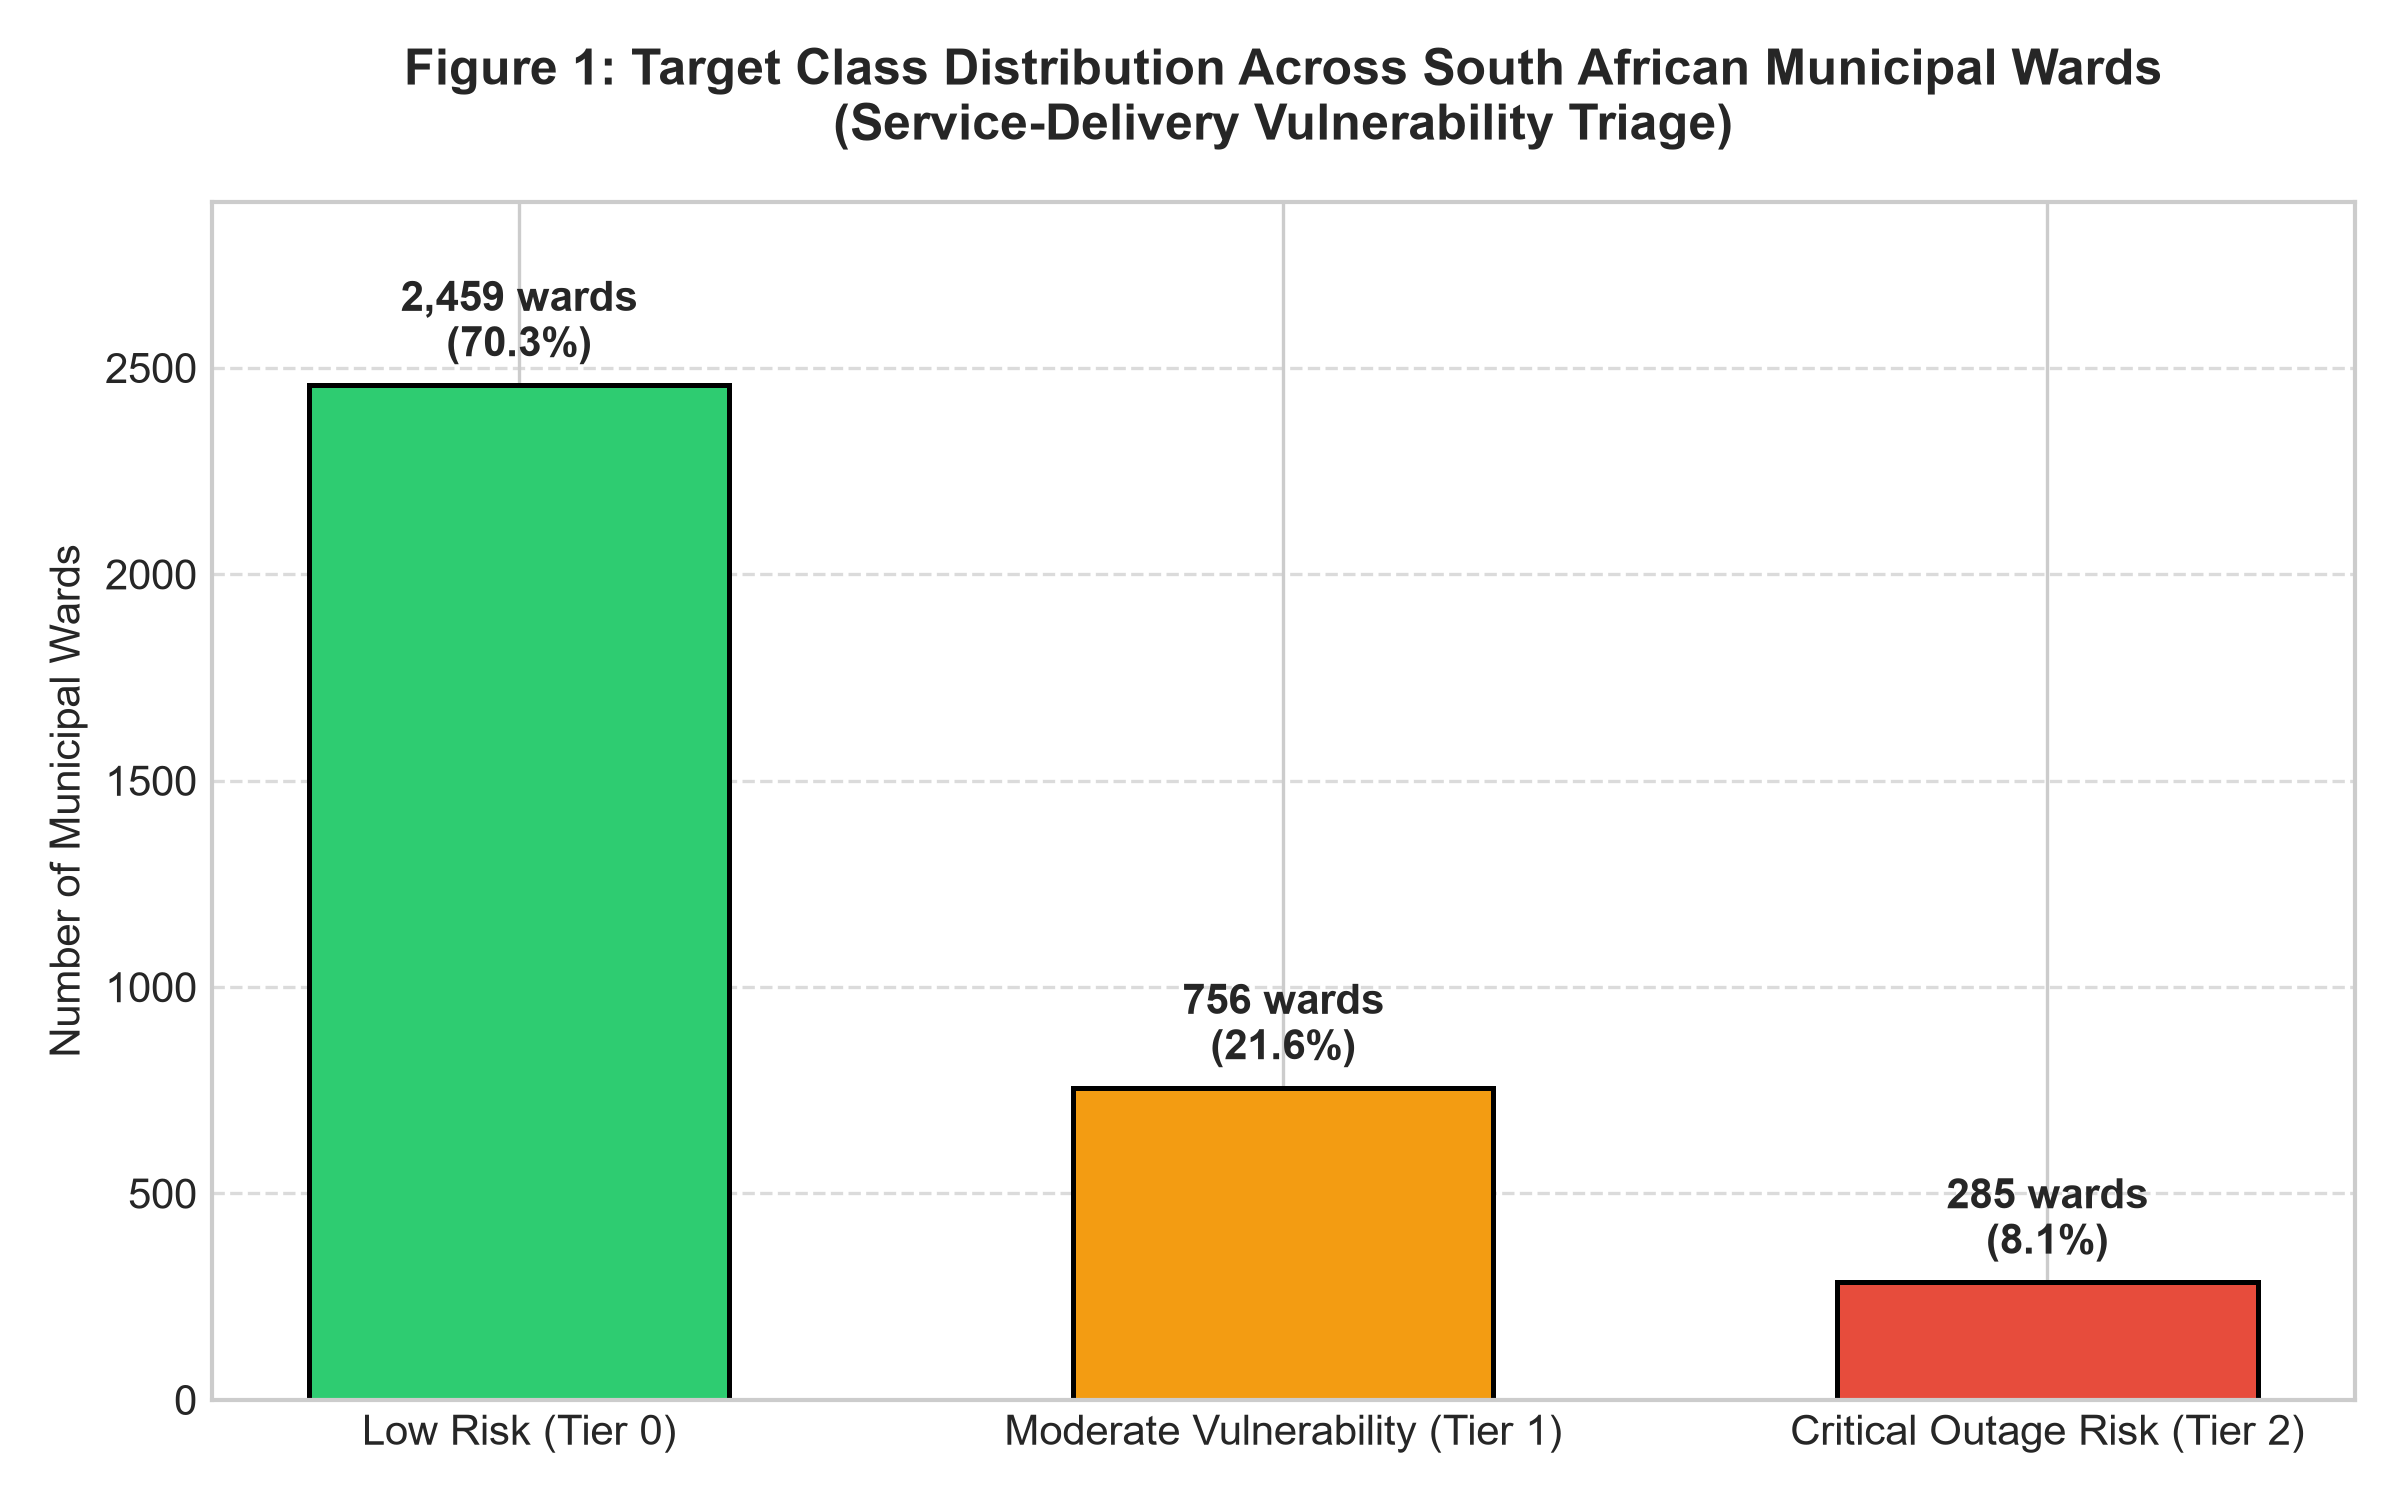

In [4]:
Image(filename=os.path.join(FIG_DIR, 'fig1_target_distribution.png'))


### Figure 2: Missingness & Quality Audit Matrix


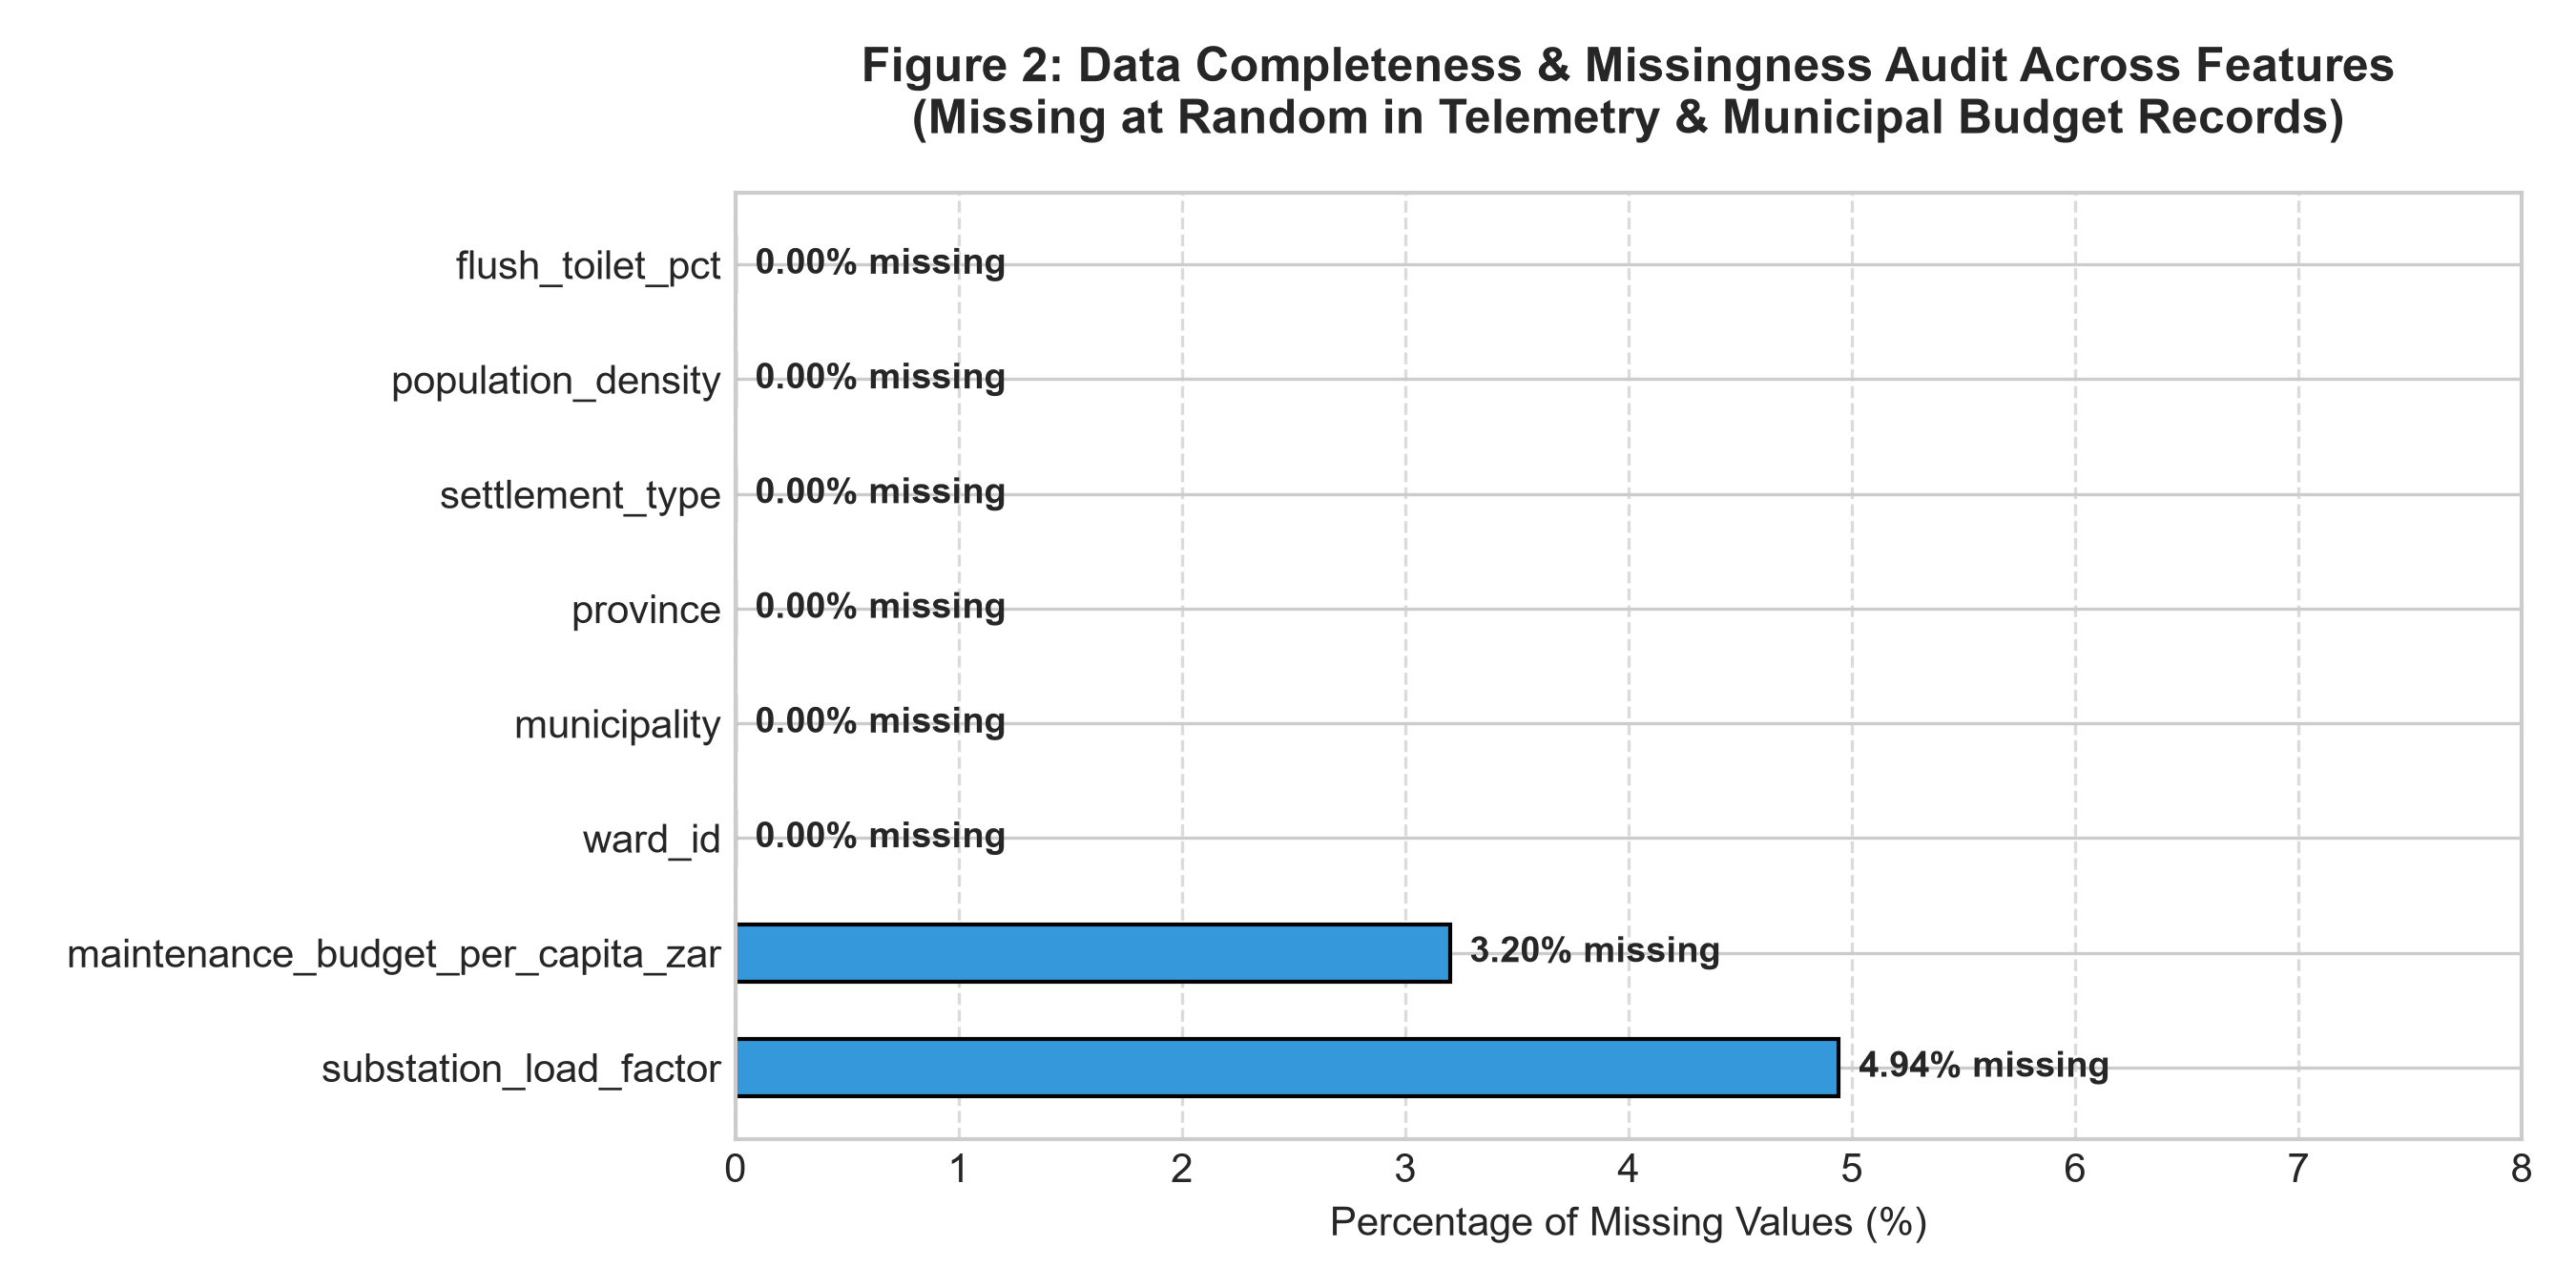

In [5]:
Image(filename=os.path.join(FIG_DIR, 'fig2_missingness_matrix.png'))


### Figure 3: Feature vs Target — Infrastructure Age vs Outage Tier


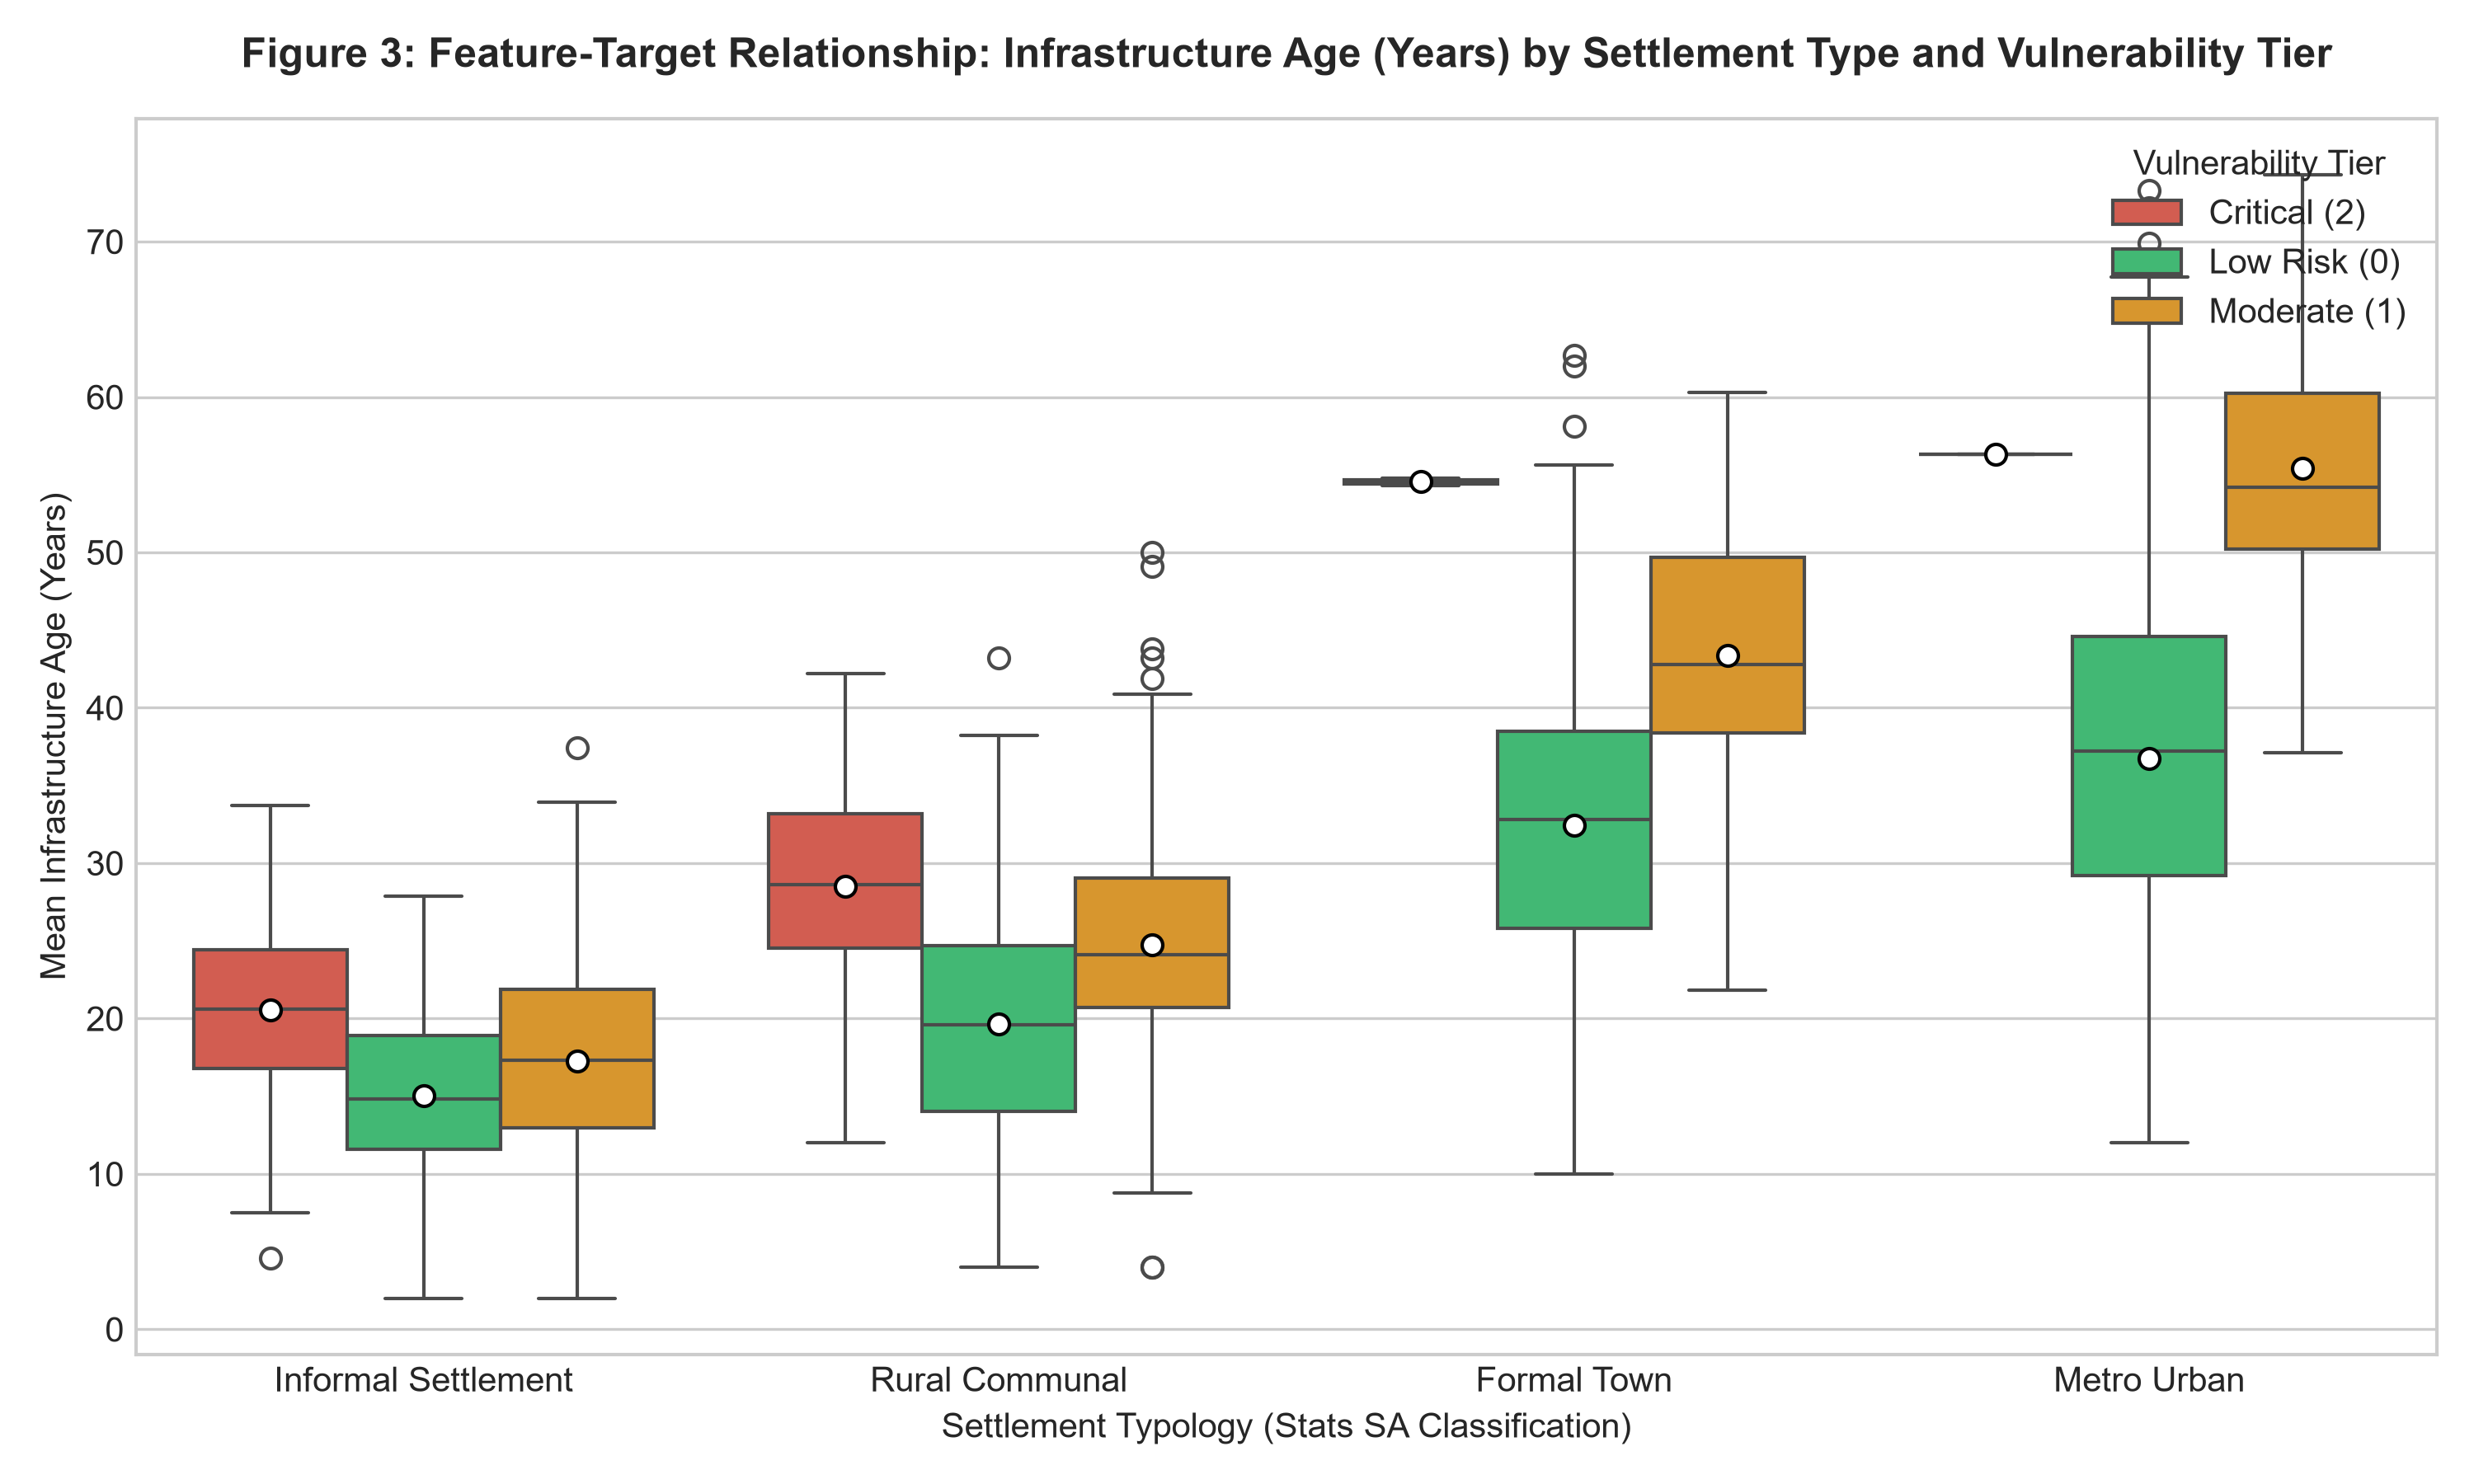

In [6]:
Image(filename=os.path.join(FIG_DIR, 'fig3_infra_age_vs_target.png'))


### Figure 4: Feature vs Target — Informal Settlement Density vs Electrical Substation Overload


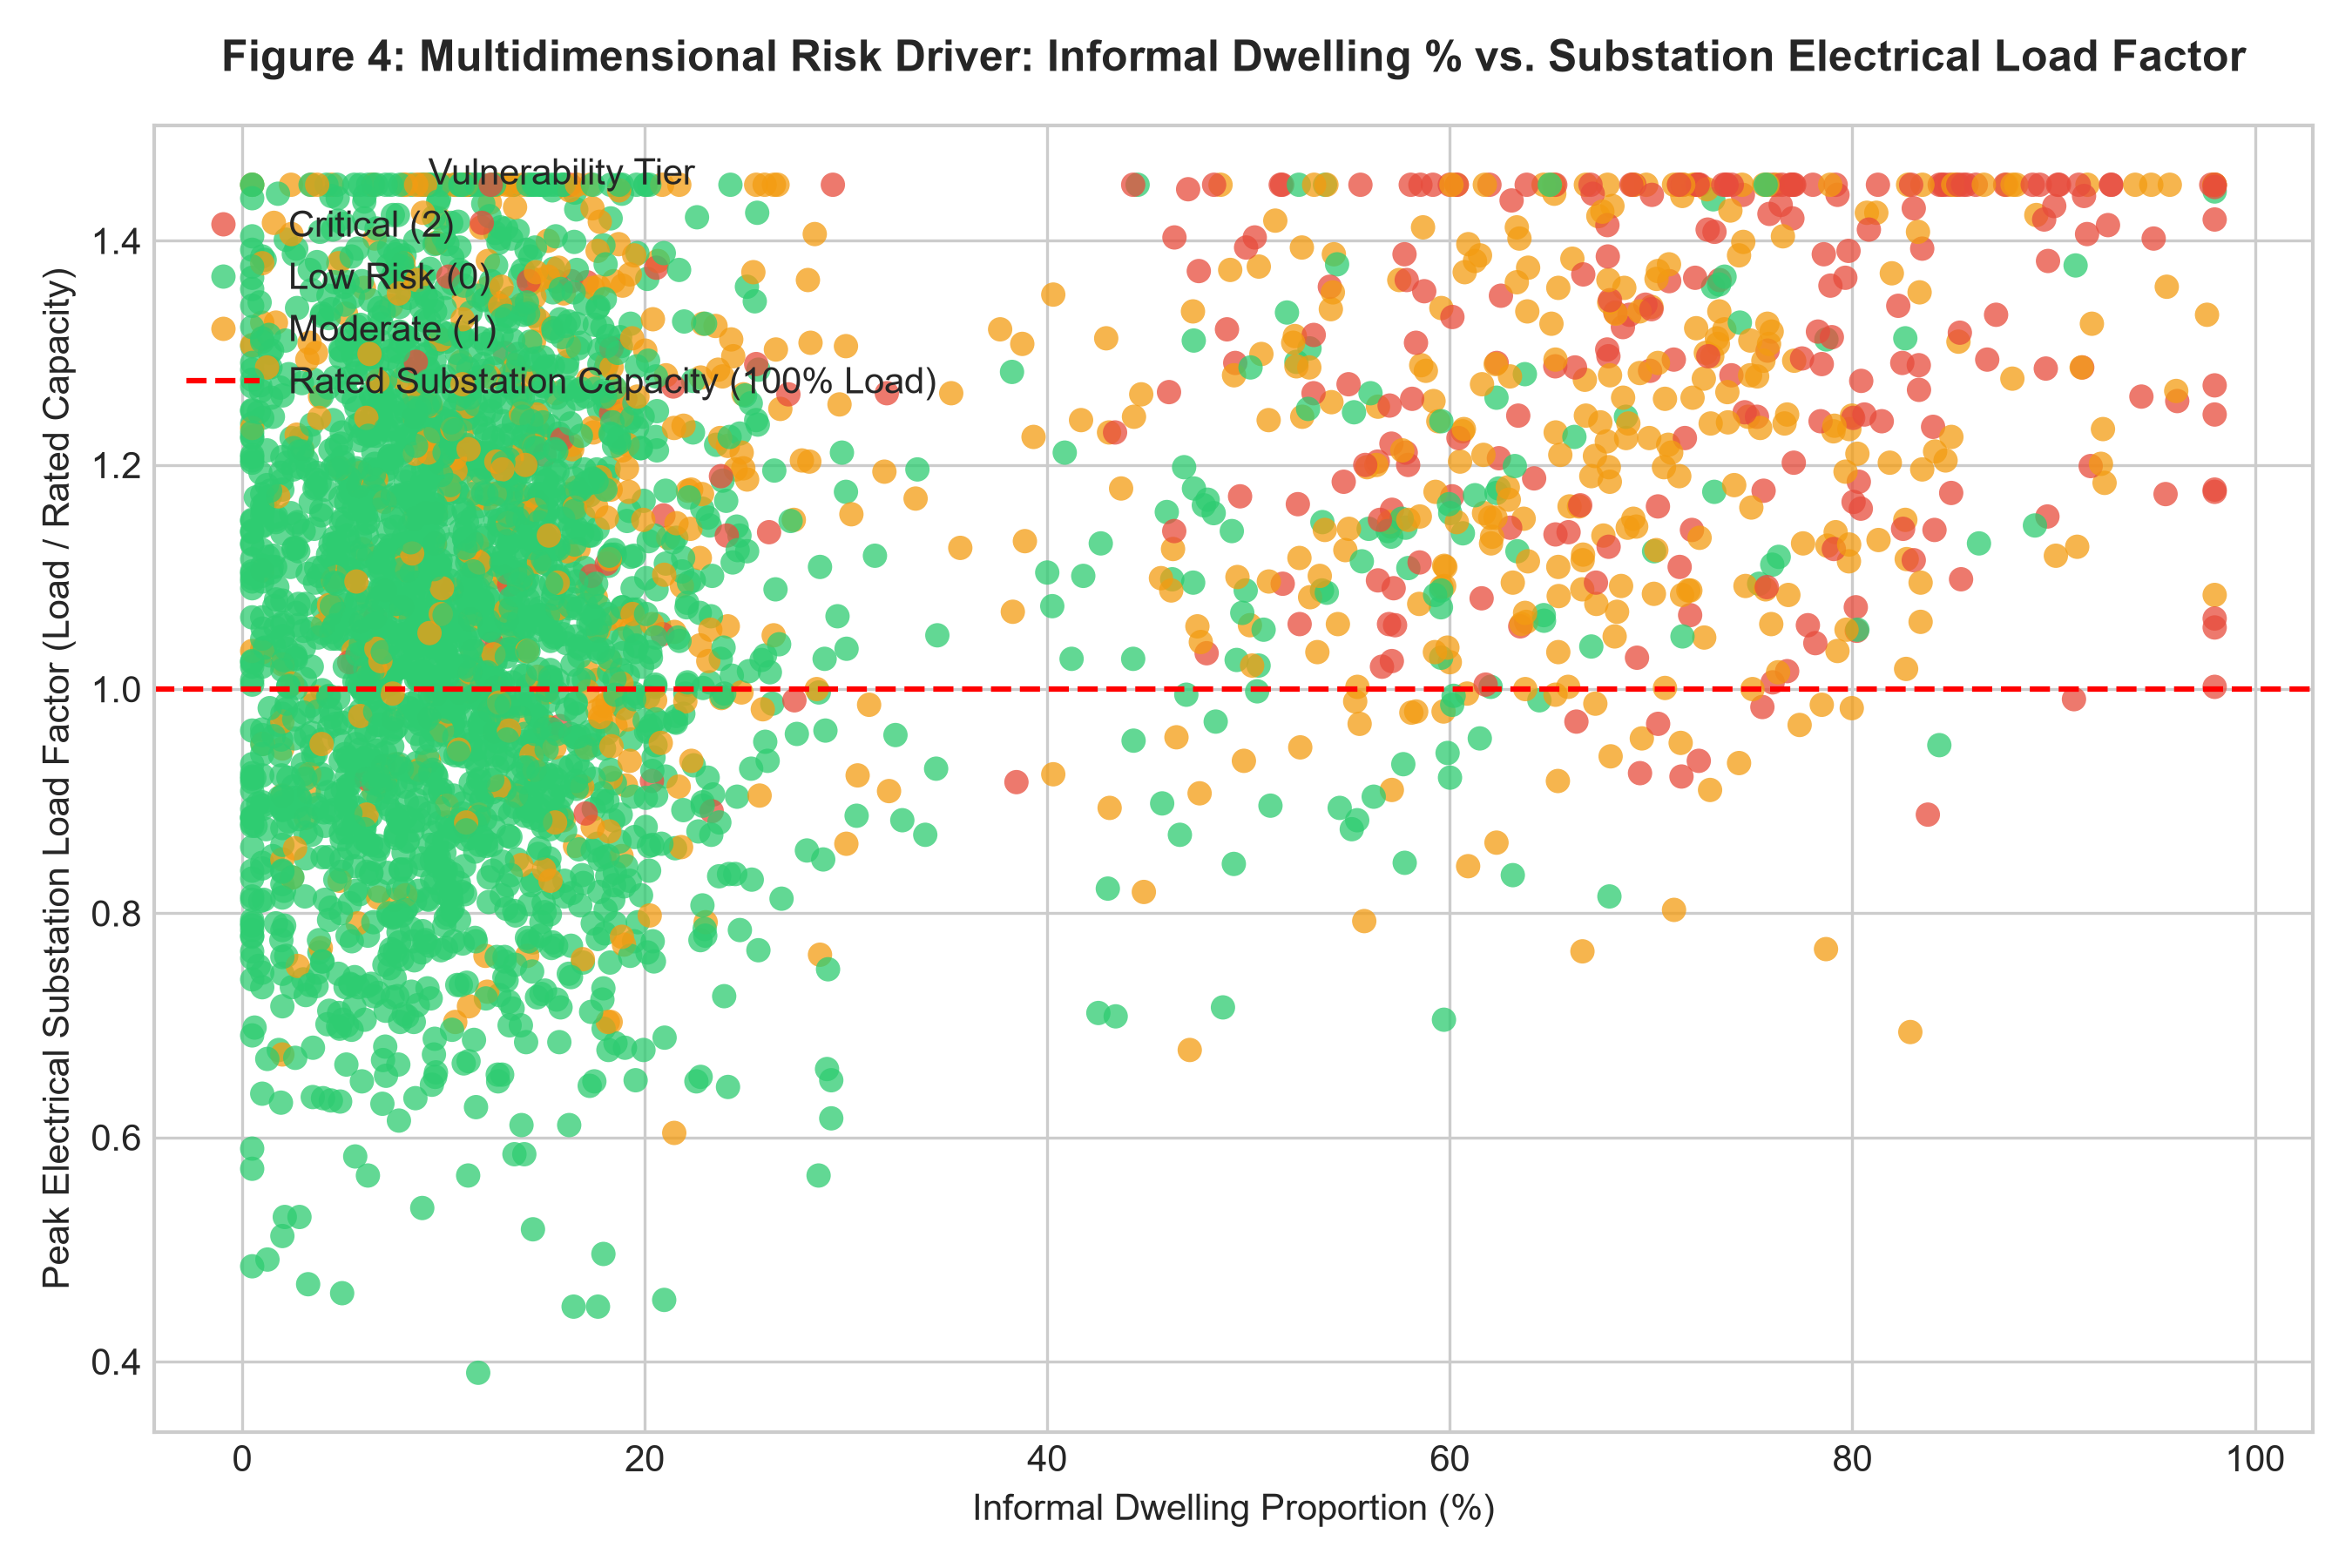

In [7]:
Image(filename=os.path.join(FIG_DIR, 'fig4_informal_vs_vulnerability.png'))


### Figure 5: Inter-Provincial Disparity Heatmap


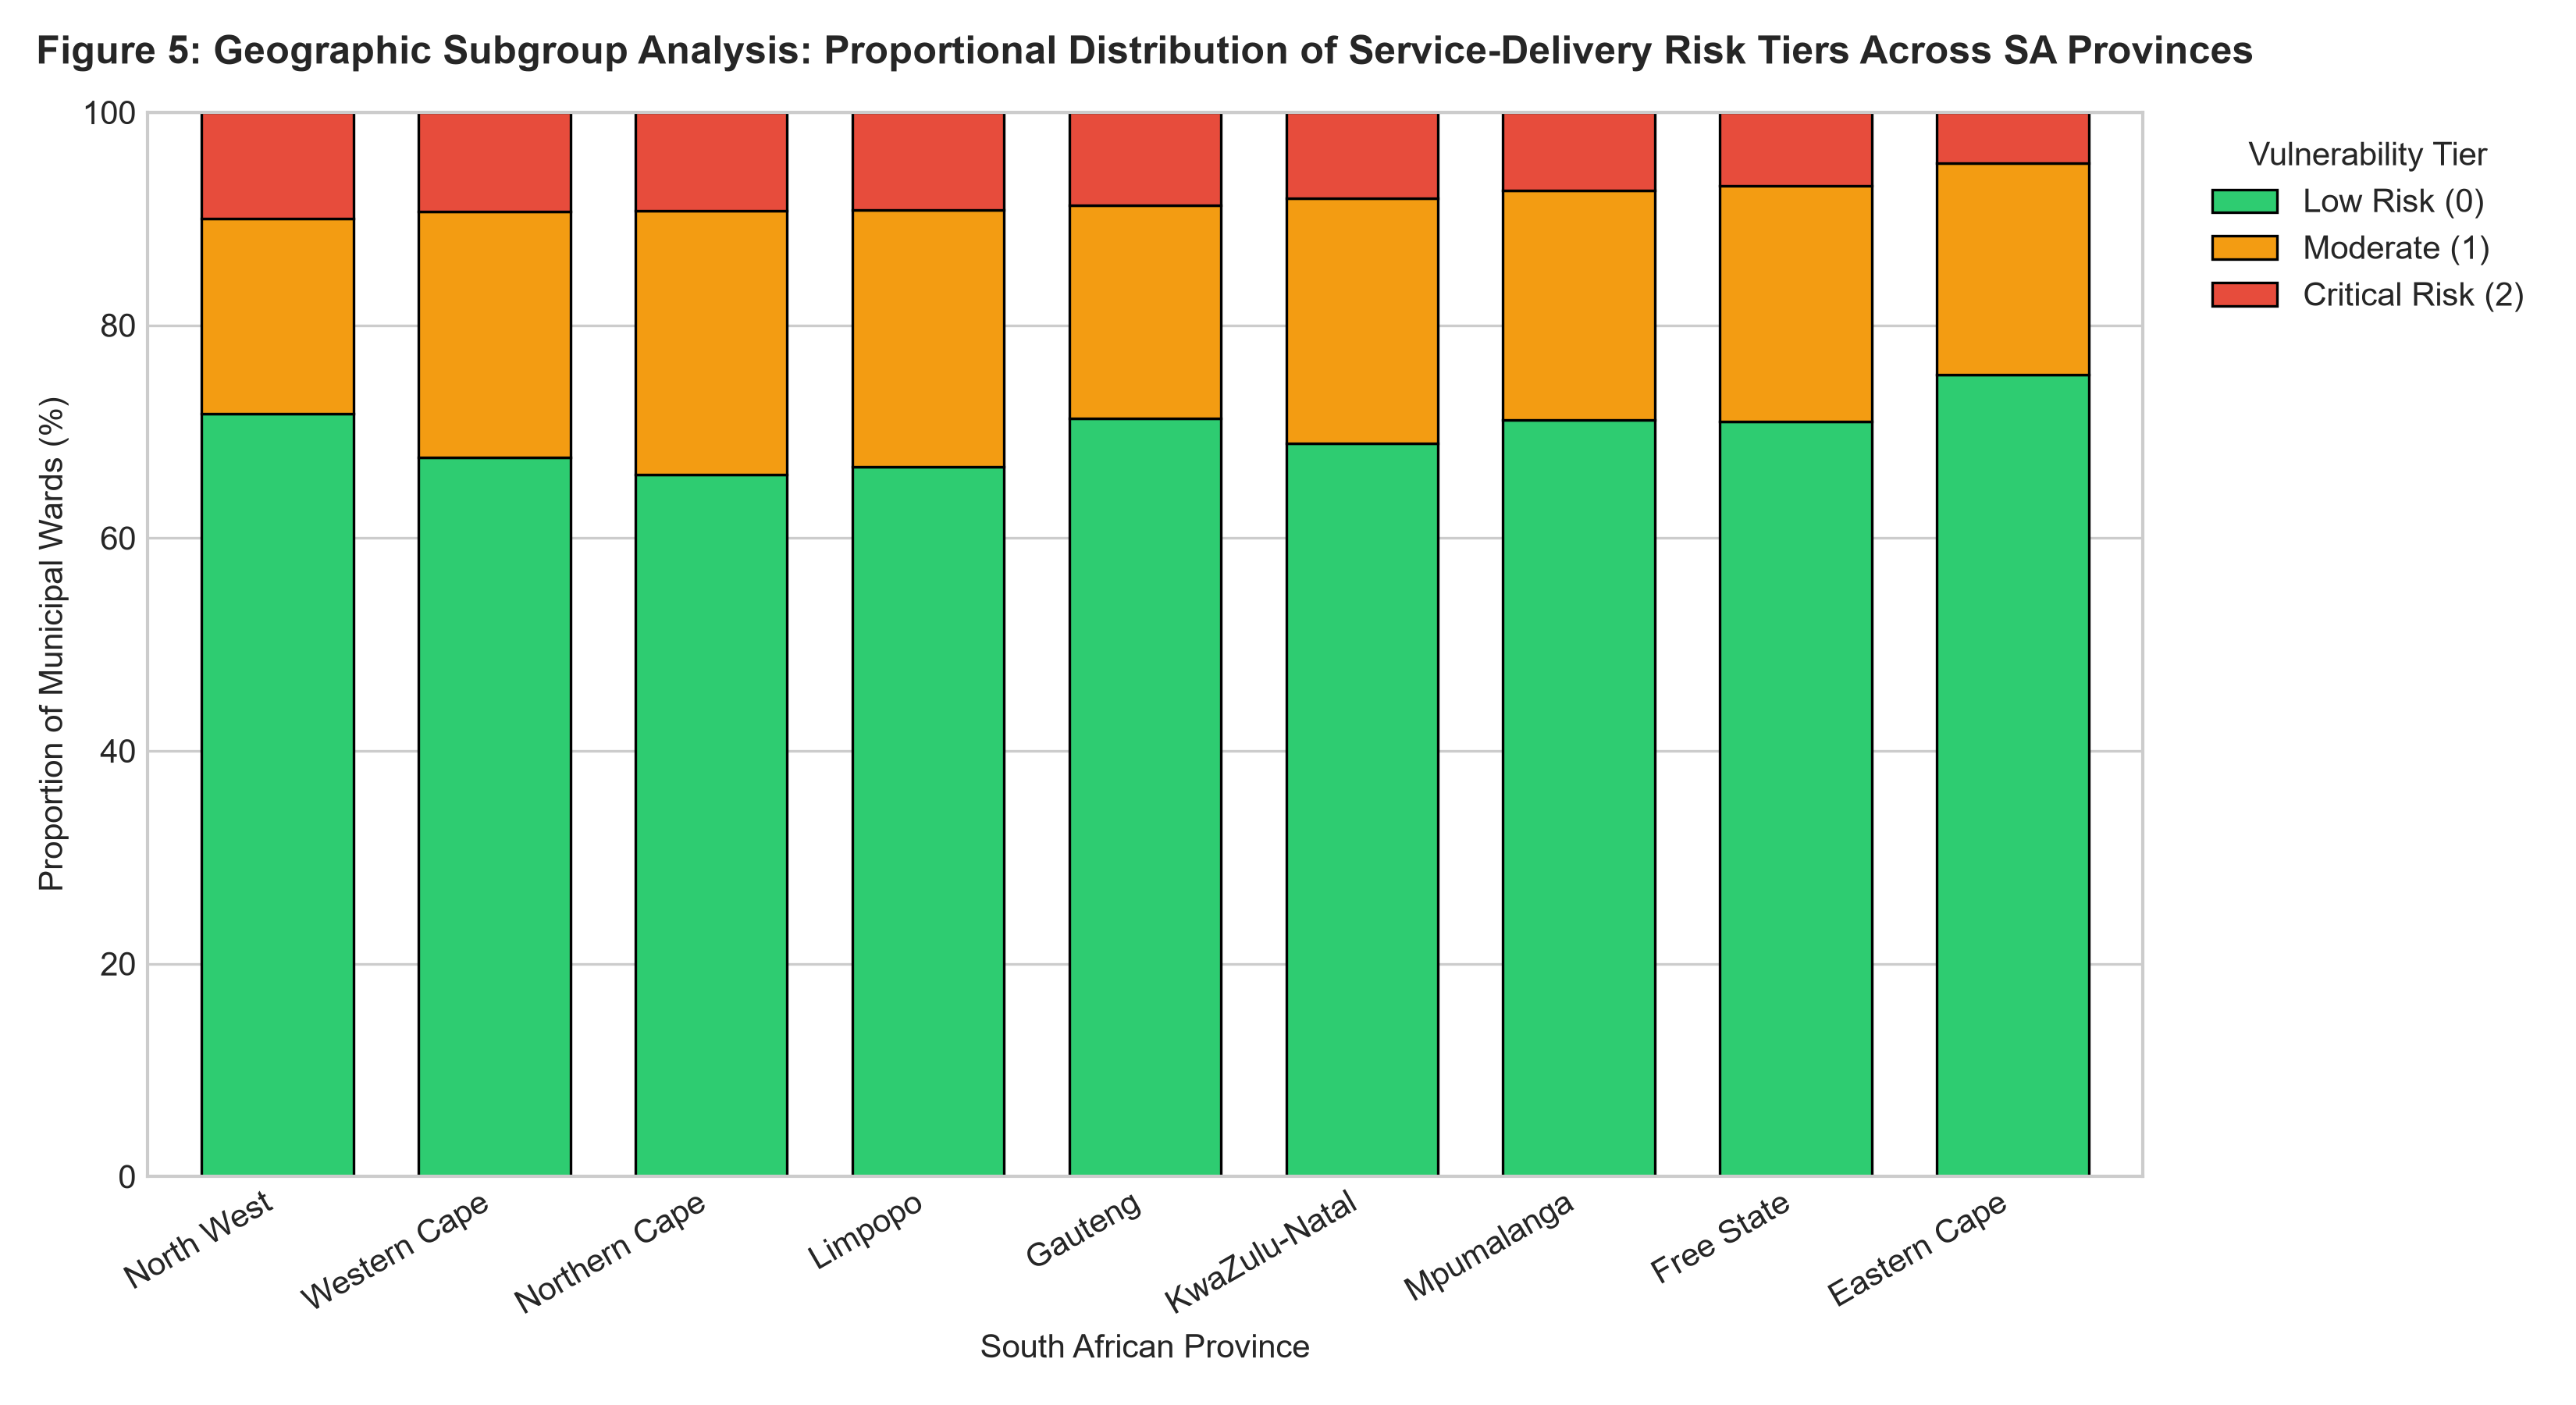

In [8]:
Image(filename=os.path.join(FIG_DIR, 'fig5_provincial_disparity.png'))
